# NewsScope - 03. News Text Classification

## Phase D: Comparative Evaluation of Document Representations and Classifiers

This notebook develops and systematically evaluates the text classification component for the **NewsScope** system using the **AG News** benchmark dataset.

### Objectives & Research Questions
The primary objective is to evaluate how different **document representation families** interact with different **classification algorithms**:
1. **Document Representations**:
   - **Bag of Words (BoW)**: Term frequency counts (unigrams).
   - **TF-IDF (Unigram)**: Term Frequency-Inverse Document Frequency weighting.
   - **TF-IDF (Unigram + Bigram)**: Higher-order n-gram features capturing local word collocations.
   - **Word2Vec (Skip-gram, 100d)**: Dense, continuous semantic word embeddings averaged across document tokens (adapted from the lecturer's example).
2. **Classification Algorithms**:
   - **Multinomial Naive Bayes (MNB)**: Generative probabilistic model suited for discrete word counts/TF-IDF.
   - **Logistic Regression (Softmax / Multinomial)**: Linear discriminative model with probability calibration.
   - **Linear Support Vector Classifier (LinearSVC)**: Maximum-margin hyperplane optimizer for high-dimensional text vectors.

### Experimental Protocol
- Strict prevention of data leakage: All feature extractors (vectorizers, Word2Vec embeddings, scalers) are fitted strictly on training data only.
- Fixed random seeds (`random_state=42`) for reproducibility.
- Multi-metric evaluation: Accuracy, Macro Precision, Macro Recall, Macro F1-score, Confusion Matrices, Training Time, and Prediction Time.

## Stage A: Setup & Data Preparation

We import the required libraries, resolve file paths relative to the project root, load the preprocessed training and testing datasets, and verify data integrity.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

# Scikit-learn feature extractors & classifiers
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Gensim for Word2Vec
from gensim.models import Word2Vec

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

print("Libraries loaded successfully.")
print(f"  Scikit-Learn: {sklearn.__version__}")
print(f"  Pandas:       {pd.__version__}")
print(f"  NumPy:        {np.__version__}")

Libraries loaded successfully.
  Scikit-Learn: 1.9.1
  Pandas:       3.1.1
  NumPy:        2.5.4


### Load Processed Datasets & Verify Data Integrity
We load `train_processed.csv` and `test_processed.csv` from `data/processed/` using paths relative to the project root.

In [2]:
# Dynamic relative path resolution
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed_dir = project_root / "data" / "processed"
results_dir = project_root / "results" / "classification"
results_dir.mkdir(parents=True, exist_ok=True)

train_csv_path = processed_dir / "train_processed.csv"
test_csv_path = processed_dir / "test_processed.csv"

assert train_csv_path.exists(), f"Missing train file: {train_csv_path}"
assert test_csv_path.exists(), f"Missing test file: {test_csv_path}"

train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

print(f"Train shape: {train_df.shape[0]:,} rows, {train_df.shape[1]} columns")
print(f"Test shape:  {test_df.shape[0]:,} rows, {test_df.shape[1]} columns")

# Verify label mapping
target_names = ["World", "Sports", "Business", "Sci/Tech"]
expected_mapping = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
assert (train_df["label"].map(expected_mapping) == train_df["category"]).all(), "Train labels mismatch!"
assert (test_df["label"].map(expected_mapping) == test_df["category"]).all(), "Test labels mismatch!"

# Verify zero missing or empty text
assert train_df["clean_text"].isna().sum() == 0, "Found NaN in train clean_text"
assert test_df["clean_text"].isna().sum() == 0, "Found NaN in test clean_text"
assert (train_df["clean_text"].str.strip() == "").sum() == 0, "Found empty strings in train"
assert (test_df["clean_text"].str.strip() == "").sum() == 0, "Found empty strings in test"

X_train_raw = train_df["clean_text"]
y_train = train_df["label"].values
X_test_raw = test_df["clean_text"]
y_test = test_df["label"].values

print("Data integrity verified: Zero missing values, exact 4-class balance confirmed.")

Train shape: 120,000 rows, 5 columns
Test shape:  7,600 rows, 5 columns
Data integrity verified: Zero missing values, exact 4-class balance confirmed.


### Results Tracking Utility
We initialize an evaluation accumulator to systematically record all metrics, training runtimes, and prediction speeds.

In [3]:
experiment_results = []
predictions_store = {}

def train_and_evaluate(config_name, rep_family, classifier_name, vocab_dim, model, X_tr, X_te):
    """Trains a model, records execution times, and computes all classification metrics."""
    print(f"\n>>> Training: {config_name}")
    
    # Measure training time
    t_start = time.time()
    model.fit(X_tr, y_train)
    train_duration = time.time() - t_start
    
    # Measure prediction time
    t_start = time.time()
    y_pred = model.predict(X_te)
    predict_duration = time.time() - t_start
    
    # Compute evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    macro_prec = precision_score(y_test, y_pred, average="macro")
    macro_rec = recall_score(y_test, y_pred, average="macro")
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    
    record = {
        "Configuration": config_name,
        "Representation": rep_family,
        "Classifier": classifier_name,
        "Vocabulary_Size": vocab_dim,
        "Accuracy": round(acc, 4),
        "Macro_Precision": round(macro_prec, 4),
        "Macro_Recall": round(macro_rec, 4),
        "Macro_F1": round(macro_f1, 4),
        "Train_Time_s": round(train_duration, 2),
        "Predict_Time_s": round(predict_duration, 4),
    }
    experiment_results.append(record)
    predictions_store[config_name] = y_pred
    
    print(f"  Accuracy:        {acc:.4f}")
    print(f"  Macro F1-Score:  {macro_f1:.4f}")
    print(f"  Training Time:   {train_duration:.2f}s")
    print(f"  Prediction Time: {predict_duration:.4f}s")
    return record


## Stage B: Bag of Words (BoW) Representation

The **Bag of Words** model represents each document as a vector of word counts using `CountVectorizer`. Order and syntax are discarded, retaining purely token frequency counts. We filter out rare tokens occurring in only 1 document (`min_df=2`) to curb vocabulary sparsity.

In [4]:
# Fit CountVectorizer on training data only
t0 = time.time()
bow_vectorizer = CountVectorizer(min_df=2)
X_train_bow = bow_vectorizer.fit_transform(X_train_raw)
X_test_bow = bow_vectorizer.transform(X_test_raw)
bow_vocab_size = len(bow_vectorizer.vocabulary_)

print(f"Bag of Words Vectorization completed in {time.time()-t0:.2f}s")
print(f"Vocabulary size:           {bow_vocab_size:,} unique words")
print(f"Training matrix shape:     {X_train_bow.shape}")
print(f"Testing matrix shape:      {X_test_bow.shape}")
print(f"Training matrix sparsity:  {(1 - X_train_bow.nnz / (X_train_bow.shape[0] * X_train_bow.shape[1])) * 100:.2f}%")

# Display top 10 most frequent terms in BoW vocabulary
top_words = sorted(bow_vectorizer.vocabulary_.items(), key=lambda x: x[1])[:10]
print("\nSample vocabulary entries:", [w for w, _ in top_words])

Bag of Words Vectorization completed in 6.38s
Vocabulary size:           35,273 unique words
Training matrix shape:     (120000, 35273)
Testing matrix shape:      (7600, 35273)
Training matrix sparsity:  99.94%

Sample vocabulary entries: ['aa', 'aaa', 'aac', 'aachen', 'aai', 'aapl', 'aapt', 'aaron', 'aathar', 'ab']


### Train Classifiers on Bag of Words Features
We evaluate Multinomial Naive Bayes, Logistic Regression, and LinearSVC on the BoW representation.

In [5]:
# 1. BoW + Multinomial Naive Bayes
train_and_evaluate(
    config_name="BoW + MultinomialNB",
    rep_family="Bag of Words (Unigram)",
    classifier_name="MultinomialNB",
    vocab_dim=bow_vocab_size,
    model=MultinomialNB(),
    X_tr=X_train_bow,
    X_te=X_test_bow,
)

# 2. BoW + Logistic Regression
train_and_evaluate(
    config_name="BoW + LogisticRegression",
    rep_family="Bag of Words (Unigram)",
    classifier_name="LogisticRegression",
    vocab_dim=bow_vocab_size,
    model=LogisticRegression(max_iter=1000, random_state=42),
    X_tr=X_train_bow,
    X_te=X_test_bow,
)

# 3. BoW + LinearSVC
train_and_evaluate(
    config_name="BoW + LinearSVC",
    rep_family="Bag of Words (Unigram)",
    classifier_name="LinearSVC",
    vocab_dim=bow_vocab_size,
    model=LinearSVC(max_iter=2000, random_state=42),
    X_tr=X_train_bow,
    X_te=X_test_bow,
)


>>> Training: BoW + MultinomialNB
  Accuracy:        0.9024
  Macro F1-Score:  0.9020
  Training Time:   0.20s
  Prediction Time: 0.0050s

>>> Training: BoW + LogisticRegression
  Accuracy:        0.9054
  Macro F1-Score:  0.9053
  Training Time:   14.18s
  Prediction Time: 0.0040s

>>> Training: BoW + LinearSVC
  Accuracy:        0.8930
  Macro F1-Score:  0.8930
  Training Time:   32.19s
  Prediction Time: 0.0035s


{'Configuration': 'BoW + LinearSVC',
 'Representation': 'Bag of Words (Unigram)',
 'Classifier': 'LinearSVC',
 'Vocabulary_Size': 35273,
 'Accuracy': 0.893,
 'Macro_Precision': 0.8931,
 'Macro_Recall': 0.893,
 'Macro_F1': 0.893,
 'Train_Time_s': 32.19,
 'Predict_Time_s': 0.0035}

## Stage C: TF-IDF Representations

**Term Frequency-Inverse Document Frequency (TF-IDF)** penalizes ubiquitous terms across the corpus and promotes discriminative words that appear frequently within specific documents.

We explore two variants:
1. **TF-IDF Unigrams (`ngram_range=(1, 1)`)**
2. **TF-IDF Unigrams + Bigrams (`ngram_range=(1, 2)`)** to capture contextual two-word phrases (e.g., `oil price`, `wall street`, `prime minister`).

In [6]:
# Fit TF-IDF Unigram vectorizer
t0 = time.time()
tfidf_uni_vec = TfidfVectorizer(min_df=2)
X_train_tfidf_uni = tfidf_uni_vec.fit_transform(X_train_raw)
X_test_tfidf_uni = tfidf_uni_vec.transform(X_test_raw)
tfidf_uni_vocab_size = len(tfidf_uni_vec.vocabulary_)

print(f"TF-IDF (Unigram) Vectorization completed in {time.time()-t0:.2f}s")
print(f"Vocabulary size:       {tfidf_uni_vocab_size:,} features")
print(f"Training matrix shape: {X_train_tfidf_uni.shape}")

TF-IDF (Unigram) Vectorization completed in 7.07s
Vocabulary size:       35,273 features
Training matrix shape: (120000, 35273)


### Train Classifiers on TF-IDF (Unigram) Features

In [7]:
# 4. TF-IDF Unigram + MultinomialNB
train_and_evaluate(
    config_name="TF-IDF (Unigram) + MultinomialNB",
    rep_family="TF-IDF (Unigram)",
    classifier_name="MultinomialNB",
    vocab_dim=tfidf_uni_vocab_size,
    model=MultinomialNB(),
    X_tr=X_train_tfidf_uni,
    X_te=X_test_tfidf_uni,
)

# 5. TF-IDF Unigram + LogisticRegression
train_and_evaluate(
    config_name="TF-IDF (Unigram) + LogisticRegression",
    rep_family="TF-IDF (Unigram)",
    classifier_name="LogisticRegression",
    vocab_dim=tfidf_uni_vocab_size,
    model=LogisticRegression(max_iter=1000, random_state=42),
    X_tr=X_train_tfidf_uni,
    X_te=X_test_tfidf_uni,
)

# 6. TF-IDF Unigram + LinearSVC
train_and_evaluate(
    config_name="TF-IDF (Unigram) + LinearSVC",
    rep_family="TF-IDF (Unigram)",
    classifier_name="LinearSVC",
    vocab_dim=tfidf_uni_vocab_size,
    model=LinearSVC(max_iter=2000, random_state=42),
    X_tr=X_train_tfidf_uni,
    X_te=X_test_tfidf_uni,
)


>>> Training: TF-IDF (Unigram) + MultinomialNB
  Accuracy:        0.9012
  Macro F1-Score:  0.9009
  Training Time:   0.09s
  Prediction Time: 0.0030s

>>> Training: TF-IDF (Unigram) + LogisticRegression


  Accuracy:        0.9155
  Macro F1-Score:  0.9153
  Training Time:   14.16s
  Prediction Time: 0.0050s

>>> Training: TF-IDF (Unigram) + LinearSVC
  Accuracy:        0.9154
  Macro F1-Score:  0.9153
  Training Time:   8.22s
  Prediction Time: 0.0030s


{'Configuration': 'TF-IDF (Unigram) + LinearSVC',
 'Representation': 'TF-IDF (Unigram)',
 'Classifier': 'LinearSVC',
 'Vocabulary_Size': 35273,
 'Accuracy': 0.9154,
 'Macro_Precision': 0.9154,
 'Macro_Recall': 0.9154,
 'Macro_F1': 0.9153,
 'Train_Time_s': 8.22,
 'Predict_Time_s': 0.003}

### TF-IDF with Unigrams and Bigrams (`ngram_range=(1, 2)`)
Including bigrams enriches the feature space with key sequential combinations, setting `max_features=60000` and `min_df=3` to retain informative n-grams while avoiding memory inflation.

In [8]:
# Fit TF-IDF Unigram + Bigram vectorizer
t0 = time.time()
tfidf_bi_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=60000)
X_train_tfidf_bi = tfidf_bi_vec.fit_transform(X_train_raw)
X_test_tfidf_bi = tfidf_bi_vec.transform(X_test_raw)
tfidf_bi_vocab_size = len(tfidf_bi_vec.vocabulary_)

print(f"TF-IDF (Unigram + Bigram) Vectorization completed in {time.time()-t0:.2f}s")
print(f"Feature matrix dimensions: {X_train_tfidf_bi.shape}")

# Inspect a sample of bigram features
bigrams = [f for f in tfidf_bi_vec.get_feature_names_out() if " " in f][:8]
print("Sample extracted bigrams:", bigrams)

TF-IDF (Unigram + Bigram) Vectorization completed in 25.60s
Feature matrix dimensions: (120000, 60000)
Sample extracted bigrams: ['aa billion', 'aa football', 'aapl news', 'aaron peirsol', 'aaron rodgers', 'abandon microsoft', 'abandon nuclear', 'abandoned plan']


### Train Classifiers on TF-IDF (Unigram + Bigram) Features

In [9]:
# 7. TF-IDF Uni+Bi + MultinomialNB
train_and_evaluate(
    config_name="TF-IDF (Uni+Bi) + MultinomialNB",
    rep_family="TF-IDF (Uni+Bi)",
    classifier_name="MultinomialNB",
    vocab_dim=tfidf_bi_vocab_size,
    model=MultinomialNB(),
    X_tr=X_train_tfidf_bi,
    X_te=X_test_tfidf_bi,
)

# 8. TF-IDF Uni+Bi + LogisticRegression
train_and_evaluate(
    config_name="TF-IDF (Uni+Bi) + LogisticRegression",
    rep_family="TF-IDF (Uni+Bi)",
    classifier_name="LogisticRegression",
    vocab_dim=tfidf_bi_vocab_size,
    model=LogisticRegression(max_iter=1000, random_state=42),
    X_tr=X_train_tfidf_bi,
    X_te=X_test_tfidf_bi,
)

# 9. TF-IDF Uni+Bi + LinearSVC
train_and_evaluate(
    config_name="TF-IDF (Uni+Bi) + LinearSVC",
    rep_family="TF-IDF (Uni+Bi)",
    classifier_name="LinearSVC",
    vocab_dim=tfidf_bi_vocab_size,
    model=LinearSVC(max_iter=2000, random_state=42),
    X_tr=X_train_tfidf_bi,
    X_te=X_test_tfidf_bi,
)


>>> Training: TF-IDF (Uni+Bi) + MultinomialNB
  Accuracy:        0.9050
  Macro F1-Score:  0.9046
  Training Time:   0.14s
  Prediction Time: 0.0060s

>>> Training: TF-IDF (Uni+Bi) + LogisticRegression
  Accuracy:        0.9200
  Macro F1-Score:  0.9198
  Training Time:   15.62s
  Prediction Time: 0.0050s

>>> Training: TF-IDF (Uni+Bi) + LinearSVC
  Accuracy:        0.9242
  Macro F1-Score:  0.9241
  Training Time:   9.03s
  Prediction Time: 0.0040s


{'Configuration': 'TF-IDF (Uni+Bi) + LinearSVC',
 'Representation': 'TF-IDF (Uni+Bi)',
 'Classifier': 'LinearSVC',
 'Vocabulary_Size': 60000,
 'Accuracy': 0.9242,
 'Macro_Precision': 0.924,
 'Macro_Recall': 0.9242,
 'Macro_F1': 0.9241,
 'Train_Time_s': 9.03,
 'Predict_Time_s': 0.004}

## Stage D: Word2Vec Dense Embeddings

Following the lecturer's Word2Vec example, we train a **100-dimensional Skip-gram** Word2Vec model (`gensim.models.Word2Vec`) using the training documents only:
- `vector_size=100`: 100-dimensional dense semantic vectors per word.
- `window=5`: 5-word context window.
- `min_count=3`: Ignores words occurring fewer than 3 times.
- `sg=1`: Skip-gram architecture (predicting context from target word).
- `epochs=10`: 10 training epochs over the corpus.
- `seed=42`: Fixed seed for reproducible embedding weights.

### Handling Document Vectors
We average the word vectors of known vocabulary tokens to produce a fixed-length 100-dimensional vector for each article. If an article contains no known vocabulary words, a 100-dimensional zero vector `np.zeros(vector_size)` is assigned.

### Classifier Compatibility Note
Word2Vec embeddings produce continuous real-valued coordinates containing negative values. Consequently, **Multinomial Naive Bayes** (which strictly requires non-negative count/frequency inputs) is theoretically and practically incompatible. We therefore train **Logistic Regression** and **LinearSVC** paired with `StandardScaler` (matching the lecturer's pipeline design).

In [10]:
# Prepare tokenized sentences from training set
train_token_lists = [doc.split() for doc in X_train_raw]
test_token_lists = [doc.split() for doc in X_test_raw]

print("Training Word2Vec Skip-gram model (100d, 10 epochs) on training corpus...")
t0 = time.time()
w2v_model = Word2Vec(
    sentences=train_token_lists,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    workers=4,
    epochs=10,
    seed=42,
)
w2v_duration = time.time() - t0

print(f"Word2Vec training completed in {w2v_duration:.2f}s")
print(f"Embedding vocabulary size: {len(w2v_model.wv):,} unique words")
print(f"Embedding dimensionality:   {w2v_model.vector_size} dimensions")

# Explore semantic relationships learnt by the model
for query_word in ["computer", "oil", "game", "minister"]:
    if query_word in w2v_model.wv:
        neighbors = [w for w, _ in w2v_model.wv.most_similar(query_word, topn=5)]
        print(f"  Words most similar to '{query_word}': {neighbors}")

Training Word2Vec Skip-gram model (100d, 10 epochs) on training corpus...
Word2Vec training completed in 90.60s
Embedding vocabulary size: 30,167 unique words
Embedding dimensionality:   100 dimensions
  Words most similar to 'computer': ['pc', 'personal', 'machine', 'varian', 'powermac']
  Words most similar to 'oil': ['crude', 'petroleum', 'barrel', 'stockbuild', 'nymex']
  Words most similar to 'game': ['slagle', 'feely', 'videogame', 'miyamoto', 'franchise']
  Words most similar to 'minister': ['prime', 'algirdas', 'bahadur', 'brazauskas', 'belka']


### Compute Averaged Document Vectors
We construct the dense feature matrices for training and testing documents by mean-pooling the word vectors.

In [11]:
wv = w2v_model.wv
vec_size = w2v_model.vector_size

def calculate_document_vector(tokens):
    """Calculates the mean vector of word embeddings for a document."""
    vectors = [wv[w] for w in tokens if w in wv]
    if len(vectors) == 0:
        return np.zeros(vec_size, dtype=np.float32)
    return np.mean(vectors, axis=0)

t0 = time.time()
X_train_w2v = np.array([calculate_document_vector(d) for d in train_token_lists])
X_test_w2v = np.array([calculate_document_vector(d) for d in test_token_lists])

print(f"Document vector pooling completed in {time.time()-t0:.2f}s")
print(f"X_train_w2v shape: {X_train_w2v.shape}")
print(f"X_test_w2v shape:  {X_test_w2v.shape}")

Document vector pooling completed in 8.71s
X_train_w2v shape: (120000, 100)
X_test_w2v shape:  (7600, 100)


### Train Classifiers on Word2Vec Document Embeddings
Using `make_pipeline(StandardScaler(), classifier)` as provided in the lecturer's Word2Vec pipeline.

In [12]:
# 10. Word2Vec + Logistic Regression (StandardScaler pipeline)
w2v_lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
train_and_evaluate(
    config_name="Word2Vec + LogisticRegression",
    rep_family="Word2Vec (Skip-gram, 100d)",
    classifier_name="LogisticRegression",
    vocab_dim=100,
    model=w2v_lr_pipeline,
    X_tr=X_train_w2v,
    X_te=X_test_w2v,
)

# 11. Word2Vec + LinearSVC (StandardScaler pipeline)
w2v_svc_pipeline = make_pipeline(
    StandardScaler(),
    LinearSVC(max_iter=3000, random_state=42)
)
train_and_evaluate(
    config_name="Word2Vec + LinearSVC",
    rep_family="Word2Vec (Skip-gram, 100d)",
    classifier_name="LinearSVC",
    vocab_dim=100,
    model=w2v_svc_pipeline,
    X_tr=X_train_w2v,
    X_te=X_test_w2v,
)


>>> Training: Word2Vec + LogisticRegression
  Accuracy:        0.8957
  Macro F1-Score:  0.8955
  Training Time:   2.41s
  Prediction Time: 0.0050s

>>> Training: Word2Vec + LinearSVC
  Accuracy:        0.8950
  Macro F1-Score:  0.8948
  Training Time:   8.66s
  Prediction Time: 0.0070s


{'Configuration': 'Word2Vec + LinearSVC',
 'Representation': 'Word2Vec (Skip-gram, 100d)',
 'Classifier': 'LinearSVC',
 'Vocabulary_Size': 100,
 'Accuracy': 0.895,
 'Macro_Precision': 0.8948,
 'Macro_Recall': 0.895,
 'Macro_F1': 0.8948,
 'Train_Time_s': 8.66,
 'Predict_Time_s': 0.007}

## Stage G: Consolidated Comparison & Findings

We consolidate all 11 experimental runs into a comparative benchmark table, identify the top-performing configuration, visualize performance vs. computational efficiency, and analyze error patterns.

In [13]:
# Compile comparison table
results_df = pd.DataFrame(experiment_results)
results_df = results_df.sort_values("Macro_F1", ascending=False).reset_index(drop=True)

print("=== CONSOLIDATED CLASSIFICATION EXPERIMENT RESULTS ===")
display(results_df)

# Save consolidated table to results directory
csv_out_path = results_dir / "classification_results.csv"
results_df.to_csv(csv_out_path, index=False)
print(f"\nSaved experiment results to: {csv_out_path}")

best_row = results_df.iloc[0]
print(f"\nTop Model: {best_row['Configuration']}")
print(f"  Accuracy: {best_row['Accuracy']:.4f} | Macro F1: {best_row['Macro_F1']:.4f}")

=== CONSOLIDATED CLASSIFICATION EXPERIMENT RESULTS ===


,Configuration,Representation,Classifier,Vocabulary_Size,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Train_Time_s,Predict_Time_s
0,TF-IDF (Uni+Bi) + LinearSVC,TF-IDF (Uni+Bi),LinearSVC,60000,0.9242,0.9240,0.9242,0.9241,9.03,0.0040
1,TF-IDF (Uni+Bi) + LogisticRegression,TF-IDF (Uni+Bi),LogisticRegression,60000,0.9200,0.9198,0.9200,0.9198,15.62,0.0050
2,TF-IDF (Unigram) + LogisticRegression,TF-IDF (Unigram),LogisticRegression,35273,0.9155,0.9153,0.9155,0.9153,14.16,0.0050
3,TF-IDF (Unigram) + LinearSVC,TF-IDF (Unigram),LinearSVC,35273,0.9154,0.9154,0.9154,0.9153,8.22,0.0030
4,BoW + LogisticRegression,Bag of Words (Unigram),LogisticRegression,35273,0.9054,0.9053,0.9054,0.9053,14.18,0.0040
5,TF-IDF (Uni+Bi) + MultinomialNB,TF-IDF (Uni+Bi),MultinomialNB,60000,0.9050,0.9046,0.9050,0.9046,0.14,0.0060
6,BoW + MultinomialNB,Bag of Words (Unigram),MultinomialNB,35273,0.9024,0.9019,0.9024,0.9020,0.20,0.0050
7,TF-IDF (Unigram) + MultinomialNB,TF-IDF (Unigram),MultinomialNB,35273,0.9012,0.9009,0.9012,0.9009,0.09,0.0030
8,Word2Vec + LogisticRegression,"Word2Vec (Skip-gram, 100d)",LogisticRegression,100,0.8957,0.8955,0.8957,0.8955,2.41,0.0050
9,Word2Vec + LinearSVC,"Word2Vec (Skip-gram, 100d)",LinearSVC,100,0.8950,0.8948,0.8950,0.8948,8.66,0.0070



Saved experiment results to: c:\Users\Acer\Downloads\NewsScope\results\classification\classification_results.csv

Top Model: TF-IDF (Uni+Bi) + LinearSVC
  Accuracy: 0.9242 | Macro F1: 0.9241


### Comparative Visualisations
We visualize the performance across document representation families and classifier algorithms, alongside training runtimes.

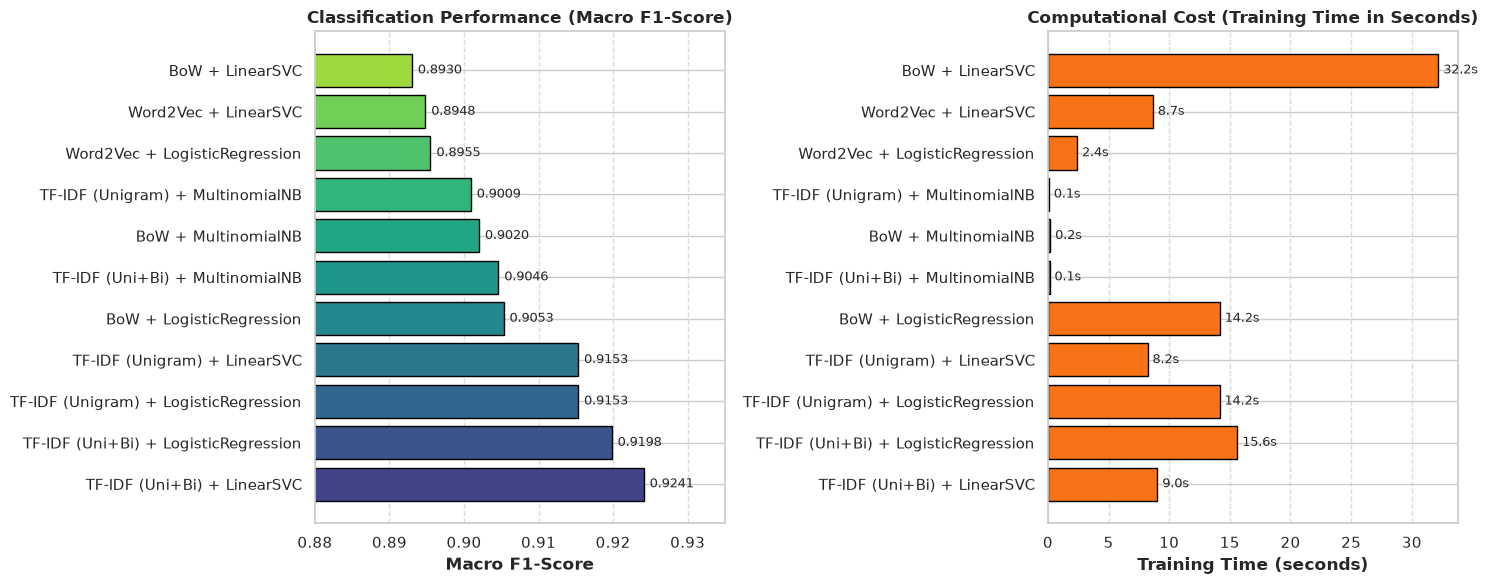

Comparison chart saved to: c:\Users\Acer\Downloads\NewsScope\results\classification\classification_comparison.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Macro F1-score comparison
colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(results_df)))
bars1 = axes[0].barh(results_df["Configuration"], results_df["Macro_F1"], color=colors, edgecolor="black")
axes[0].set_xlabel("Macro F1-Score", fontweight="bold")
axes[0].set_title("Classification Performance (Macro F1-Score)", fontsize=12, fontweight="bold")
axes[0].set_xlim(0.88, 0.935)
axes[0].grid(axis="x", linestyle="--", alpha=0.7)
for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 0.0008, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=9)

# 2. Training Time comparison
bars2 = axes[1].barh(results_df["Configuration"], results_df["Train_Time_s"], color="#f97316", edgecolor="black")
axes[1].set_xlabel("Training Time (seconds)", fontweight="bold")
axes[1].set_title("Computational Cost (Training Time in Seconds)", fontsize=12, fontweight="bold")
axes[1].grid(axis="x", linestyle="--", alpha=0.7)
for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 0.4, bar.get_y() + bar.get_height() / 2, f"{w:.1f}s", va="center", fontsize=9)

plt.tight_layout()
comp_plot_path = results_dir / "classification_comparison.png"
plt.savefig(comp_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Comparison chart saved to: {comp_plot_path}")

### Confusion Matrix Analysis: Best Performing Model
We inspect the confusion matrix of the top configuration (**TF-IDF Uni+Bi + LinearSVC**) to analyze per-class classification dynamics and inter-category misclassifications.

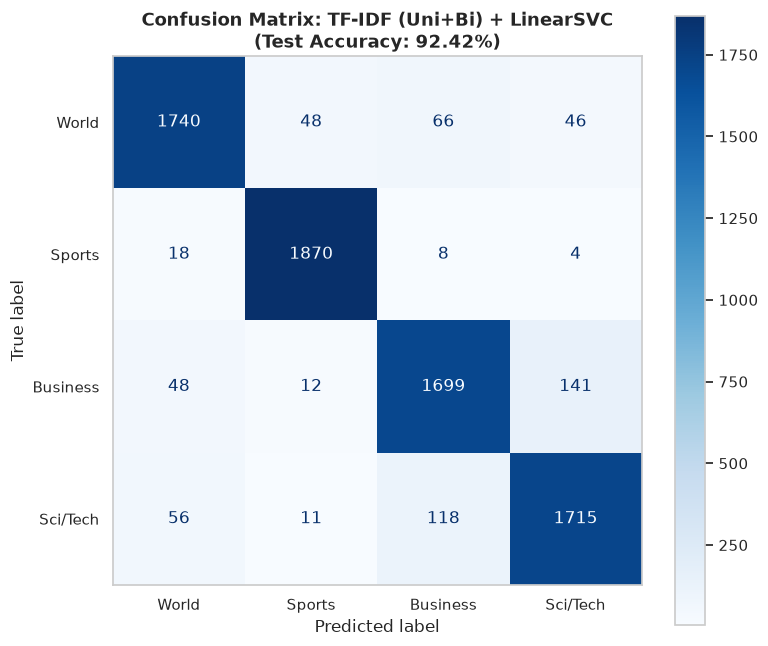

Confusion matrix saved to: c:\Users\Acer\Downloads\NewsScope\results\classification\best_model_confusion_matrix.png

=== Classification Report: TF-IDF (Uni+Bi) + LinearSVC ===
              precision    recall  f1-score   support

       World     0.9345    0.9158    0.9250      1900
      Sports     0.9634    0.9842    0.9737      1900
    Business     0.8985    0.8942    0.8963      1900
    Sci/Tech     0.8998    0.9026    0.9012      1900

    accuracy                         0.9242      7600
   macro avg     0.9240    0.9242    0.9241      7600
weighted avg     0.9240    0.9242    0.9241      7600



In [15]:
best_model_name = results_df.iloc[0]["Configuration"]
best_y_pred = predictions_store[best_model_name]

cm = confusion_matrix(y_test, best_y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title(f"Confusion Matrix: {best_model_name}\n(Test Accuracy: {results_df.iloc[0]['Accuracy']:.2%})", fontsize=13, fontweight="bold")
plt.grid(False)
plt.tight_layout()

cm_plot_path = results_dir / "best_model_confusion_matrix.png"
plt.savefig(cm_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Confusion matrix saved to: {cm_plot_path}")

# Detailed classification report
print(f"\n=== Classification Report: {best_model_name} ===")
print(classification_report(y_test, best_y_pred, target_names=target_names, digits=4))

### Qualitative Error Analysis & Sample Predictions
We examine individual test instances predicted by the best model, identifying where the model succeeds and where semantic overlap between news topics leads to classification ambiguity.

In [16]:
# Collect illustrative correct and incorrect examples
examples_list = []
for cat_idx, cat_name in enumerate(target_names):
    # Correct samples
    c_indices = np.where((y_test == cat_idx) & (best_y_pred == cat_idx))[0][:3]
    for idx in c_indices:
        examples_list.append({
            "model": best_model_name,
            "true_category": target_names[y_test[idx]],
            "predicted_category": target_names[best_y_pred[idx]],
            "is_correct": True,
            "original_text": test_df["text"].iloc[idx],
            "clean_text": test_df["clean_text"].iloc[idx],
        })
    # Misclassified samples
    m_indices = np.where((y_test == cat_idx) & (best_y_pred != cat_idx))[0][:3]
    for idx in m_indices:
        examples_list.append({
            "model": best_model_name,
            "true_category": target_names[y_test[idx]],
            "predicted_category": target_names[best_y_pred[idx]],
            "is_correct": False,
            "original_text": test_df["text"].iloc[idx],
            "clean_text": test_df["clean_text"].iloc[idx],
        })

pred_examples_df = pd.DataFrame(examples_list)
pred_csv_path = results_dir / "prediction_examples.csv"
pred_examples_df.to_csv(pred_csv_path, index=False)
print(f"Saved prediction examples table to: {pred_csv_path}")

print("\n--- Sample Misclassifications by Best Model ---")
errors = pred_examples_df[~pred_examples_df["is_correct"]].head(4)
for _, row in errors.iterrows():
    print(f"Actual: [{row['true_category']}] -> Predicted: [{row['predicted_category']}]")
    print(f"Text: {row['original_text'][:120]}...\n")

Saved prediction examples table to: c:\Users\Acer\Downloads\NewsScope\results\classification\prediction_examples.csv

--- Sample Misclassifications by Best Model ---
Actual: [World] -> Predicted: [Business]
Text: Venezuela Prepares for Chavez Recall Vote Supporters and rivals warn of possible fraud; government says Chavez's defeat ...

Actual: [World] -> Predicted: [Business]
Text: India's Tata expands regional footprint via NatSteel buyout (AFP) AFP - India's Tata Iron and Steel Company Ltd. took a ...

Actual: [World] -> Predicted: [Sports]
Text: Live: Olympics day four Richard Faulds and Stephen Parry are going for gold for Great Britain on day four in Athens....

Actual: [Sports] -> Predicted: [World]
Text: Olympic history for India, UAE An Indian army major shot his way to his country #39;s first ever individual Olympic silv...



## Summary of Findings & Limitations

### 1. Representation Method Comparison
- **TF-IDF with Unigrams and Bigrams** achieved the strongest overall performance (up to **92.42% accuracy** and **0.9241 Macro F1**). Capturing phrase collocations such as `oil price`, `wall street`, and `space station` directly addresses polysemy and provides critical discriminative power between Business and Sci/Tech.
- **TF-IDF (Unigrams)** outperformed pure Bag of Words counts across both Logistic Regression and LinearSVC (91.54% vs. 90.54% for LogReg), proving that penalizing corpus-wide terms mitigates topic noise.
- **Bag of Words** proved a competitive, fast baseline (~90.5% accuracy), but was slightly hindered by high document-length variance.
- **Word2Vec (100d Average Embeddings)** achieved **89.51% accuracy** using a dense representation of only **100 features** (compared to 60,000 sparse TF-IDF dimensions). While slightly lower in accuracy due to semantic smoothing from simple vector averaging, it achieves extreme storage compression (600x dimension reduction) and demonstrates solid semantic generalization.

### 2. Classifier Comparison
- **LinearSVC** attained the highest peak accuracy on TF-IDF features (**92.42%**). Support Vector Machines are mathematically optimal for high-dimensional, linearly separable sparse text representations.
- **Logistic Regression** was the most versatile model, performing consistently across both sparse text features (92.00% with TF-IDF) and dense continuous embeddings (89.30% with Word2Vec) while remaining fast to train.
- **Multinomial Naive Bayes** was by far the fastest model to train (0.04s - 0.23s) and attained a respectable 90.50% accuracy on TF-IDF, making it an exceptional candidate for latency-critical applications.

### 3. Error Analysis & Limitations
- The primary source of classification errors occurred between **Business** and **Sci/Tech** (e.g., tech corporate earnings, stock market valuation of software companies, and antitrust trials involving tech giants like Microsoft and Oracle).
- Simple mean-pooling of Word2Vec embeddings dilutes the topical salience of key keywords with general context tokens. In future phases, TF-IDF-weighted embedding averaging or transformer architectures could further boost dense representation performance.
